# Video Game Sales Prediction on Steam Data
## Notebook 3 of 3 — Modeling, Validation and Decision Making

Three regression models are trained to predict estimated owners (in millions) from the 42 features
built in Notebook 1: **Linear Regression** and **Decision Tree**, the two models of the parent
paper, and **Random Forest**. All models use their standard default settings. The purpose of this
notebook is to establish baseline performance and to identify the issues that later modifications
should address.

In [1]:
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
BLUE, GREEN, ORANGE, RED, GREY = "#4C72B0", "#55A868", "#DD8452", "#C44E52", "#8C8C8C"
MODEL_ORDER = ["Baseline (mean)", "Linear Regression", "Decision Tree", "Random Forest"]
MODEL_COLORS = dict(zip(MODEL_ORDER, [GREY, BLUE, ORANGE, GREEN]))
RANDOM_STATE = 42

def range_label(text):
    # "20000 - 50000" -> "20k–50k"; "1000000 - 2000000" -> "1M–2M"
    def short(n):
        n = int(n)
        if n >= 1_000_000:
            return f"{n // 1_000_000}M"
        return f"{n // 1000}k" if n >= 1000 else str(n)
    lo, hi = text.split(" - ")
    return f"{short(lo)}–{short(hi)}"


FIG_DIR = os.path.join("..", "outputs", "figures")
TAB_DIR = os.path.join("..", "outputs", "tables")
DATA_DIR = os.path.join("..", "data", "processed")

data = pd.read_csv(os.path.join(DATA_DIR, "steam_model_table.csv.gz"), parse_dates=["release_dt"])
with open(os.path.join(DATA_DIR, "features.json")) as f:
    spec = json.load(f)
TARGET = spec["target"]
FEATURES = spec["numeric"] + spec["genres"] + spec["categories"]
print(f"{len(data):,} games | {len(FEATURES)} features | target: {TARGET}")

76,727 games | 42 features | target: owners_millions


---
# 5. Data Split

## 5.1 Training and test sets

The data are split at random into a **training set (80%)** and a **test set (20%)**. The training
set is used to fit the models and to run cross-validation. The test set is set aside and used only
once, in Section 7, to measure performance on games the models have never seen. Evaluating a model
on the same data it was trained on, as the parent paper's final predictions did, overstates its
accuracy because the model has already seen the answers.

A fixed random seed (`random_state = 42`) makes the split reproducible.

In [2]:
train, test = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

split_table = pd.DataFrame({
    "Games": [len(train), len(test)],
    "Mean owners (millions)": [y_train.mean(), y_test.mean()],
    "Median owners (millions)": [y_train.median(), y_test.median()],
    "Max owners (millions)": [y_train.max(), y_test.max()],
}, index=["Training set (80%)", "Test set (20%)"])
split_table.to_csv(os.path.join(TAB_DIR, "table3_data_split.csv"))
split_table.style.format({"Games": "{:,}", "Mean owners (millions)": "{:.4f}", "Median owners (millions)": "{:.3f}",
                          "Max owners (millions)": "{:.1f}"}).set_caption("Table 3. Training and test sets")

,Games,Mean owners (millions),Median owners (millions),Max owners (millions)
Training set (80%),"61,381",0.1246,0.010,150.0
Test set (20%),"15,346",0.1298,0.010,150.0


## 5.2 Five-fold cross-validation

A single train/test split gives one estimate of performance, which depends on which games happen to
fall into the test set. **5-fold cross-validation** gives a more reliable estimate: the training set
is divided into five equal parts (folds); each model is trained on four folds and evaluated on the
fifth, and this is repeated five times so that every training game is used for evaluation once. The
mean and standard deviation over the five folds are reported. This plays the role of the parent
paper's "Test and Score" evaluation in Orange.

## 5.3 Evaluation metrics

The five metrics of the parent paper are used, all computed on owners in millions:

| Metric | Interpretation |
|---|---|
| MSE | Mean squared error; heavily penalises large errors |
| RMSE | Square root of MSE, in millions of owners |
| MAE | Mean absolute error, in millions of owners |
| MAPE (%) | Mean absolute error as a percentage of the actual value |
| R² | Share of the variance in owners explained by the model; 0 = no better than predicting the mean, negative = worse than the mean |

In [3]:
def compute_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return {
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MAPE (%)": 100 * np.mean(np.abs(y_pred - y_true) / y_true),
        "R2": r2_score(y_true, y_pred),
    }


cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X_train))


def cross_validate_model(model):
    rows = []
    for k, (tr, va) in enumerate(folds):
        m = clone(model).fit(X_train.iloc[tr], y_train.iloc[tr])
        rows.append({"fold": k + 1, **compute_metrics(y_train.iloc[va], m.predict(X_train.iloc[va]))})
    return pd.DataFrame(rows).set_index("fold")


cv_results = {}

---
# 6. Modeling

## 6.1 Baseline

A model that always predicts the mean number of owners in the training data. It uses no features and
defines the minimum performance a useful model must exceed.

In [4]:
baseline = DummyRegressor(strategy="mean")
cv_results["Baseline (mean)"] = cross_validate_model(baseline)
cv_results["Baseline (mean)"].round(4)

,MSE,RMSE,MAE,MAPE (%),R2
fold,,,,,
1,2.8381,1.6847,0.1854,852.8151,-0.0
2,3.0565,1.7483,0.1968,822.4863,-0.0
3,1.4685,1.2118,0.1901,834.6756,-0.0
4,1.3741,1.1722,0.1872,851.8214,-0.0
5,2.8057,1.6750,0.1888,842.2240,-0.0


## 6.2 Linear Regression

**Method.** Ordinary least squares fits one coefficient per feature so that the weighted sum of the
features minimises the squared difference from the actual number of owners. It is the model the
parent paper selected. Its main strength is interpretability: each coefficient states how the
prediction changes when that feature increases by one unit and all other features stay the same.

**Assumption.** The model assumes that each feature affects sales linearly and independently of the
others. Notebook 2 showed that the target is extremely skewed; how well a linear model copes with
this is part of what the baseline measures.

In [5]:
lin_reg = LinearRegression()
cv_results["Linear Regression"] = cross_validate_model(lin_reg)
cv_results["Linear Regression"].round(4)

,MSE,RMSE,MAE,MAPE (%),R2
fold,,,,,
1,2.7721,1.6650,0.2322,1147.6349,0.0232
2,2.9431,1.7155,0.2333,1073.6301,0.0370
3,1.3670,1.1692,0.2348,1139.1141,0.0691
4,1.2949,1.1380,0.2314,1169.2544,0.0576
5,2.7187,1.6488,0.2319,1145.8219,0.0310


**Results.** Linear Regression explains about 4% of the variance in owners (R² = 0.044 ± 0.019). Its mean absolute error (0.233 million) is higher than the baseline's (0.190 million): the model improves the squared-error measures slightly by moving predictions towards the large games, but becomes less accurate for the typical game.

**Coefficients.** The model is fitted on the full training set. As in the parent paper's Table III,
coefficients are reported in the original units: the change in predicted owners (in millions) for
a one-unit increase in the feature.

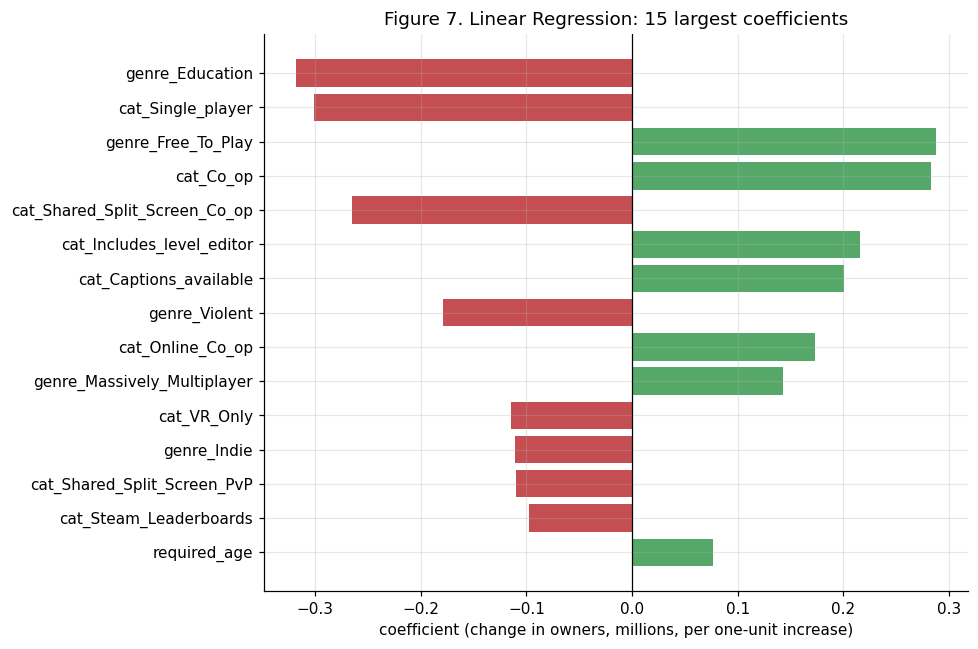

,coefficient
(intercept),60.751630
price,0.003583
release_year,-0.029942
required_age,0.076385
n_languages,0.010345
n_audio_languages,-0.007306
mac,0.011152
linux,0.050933
n_screenshots,0.004851
description_length,0.000009


In [6]:
lin_reg_fit = clone(lin_reg).fit(X_train, y_train)
coef = pd.Series(lin_reg_fit.coef_, index=FEATURES)
coef_table = pd.concat([pd.Series({"(intercept)": lin_reg_fit.intercept_}), coef]).rename("coefficient").to_frame()
coef_table.to_csv(os.path.join(TAB_DIR, "table4_linear_regression_coefficients.csv"))

top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color=np.where(top.values > 0, GREEN, RED))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("coefficient (change in owners, millions, per one-unit increase)")
ax.set_title("Figure 7. Linear Regression: 15 largest coefficients")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig07_linear_regression_coefficients.png"), dpi=150)
plt.show()
coef_table.loc[["(intercept)"] + spec["numeric"]].style.format("{:.6f}") \
    .set_caption("Table 4. Linear Regression coefficients for the numeric features (full table saved to outputs/tables)")

**Interpretation.**
- **Scale of the effects.** Most binary features have coefficients between 0.1 and 0.3 million owners, for example free-to-play +0.29, co-op +0.28, single-player −0.30 and education −0.32. These values are 10 to 30 times the owner count of the typical game (0.01 million). The fit is driven by the large games, and the coefficients do not describe the typical release.
- **Direction.** The signs agree with Notebook 2: online and multiplayer design, free-to-play, level-editor support and captions are positive; education, violent content, VR-only and split-screen co-op are negative.
- **Numeric features.** Each additional supported language adds about 0.010 million predicted owners, each dollar of price 0.004 million, each year of required age 0.076 million, and each later release year subtracts 0.030 million. The large intercept (60.8) has no direct meaning: it is the prediction for a game released in year 0 and is offset by the release-year coefficient (about −60.5 for a 2020 release).

## 6.3 Decision Tree

**Method.** A regression tree splits the games repeatedly on the feature threshold that most reduces
the squared error, and predicts the mean number of owners of the training games in each final
group (leaf). It can represent non-linear effects and interactions between features without
specifying them in advance, and its splits can be read as decision rules. It is the second model
of the parent paper.

**Settings.** The scikit-learn defaults are used: the tree grows until every leaf is pure or
contains a single game, with no limit on depth.

In [7]:
decision_tree = DecisionTreeRegressor(random_state=RANDOM_STATE)
cv_results["Decision Tree"] = cross_validate_model(decision_tree)
cv_results["Decision Tree"].round(4)

,MSE,RMSE,MAE,MAPE (%),R2
fold,,,,,
1,2.9592,1.7202,0.1460,294.0552,-0.0427
2,2.2920,1.5139,0.1753,315.8653,0.2501
3,3.9088,1.9771,0.1824,487.2778,-1.6617
4,7.8500,2.8018,0.2128,610.9313,-4.7129
5,4.8001,2.1909,0.1818,364.0878,-0.7108


Fitted tree on the training set: depth 47, 20,989 leaves for 61,381 training games


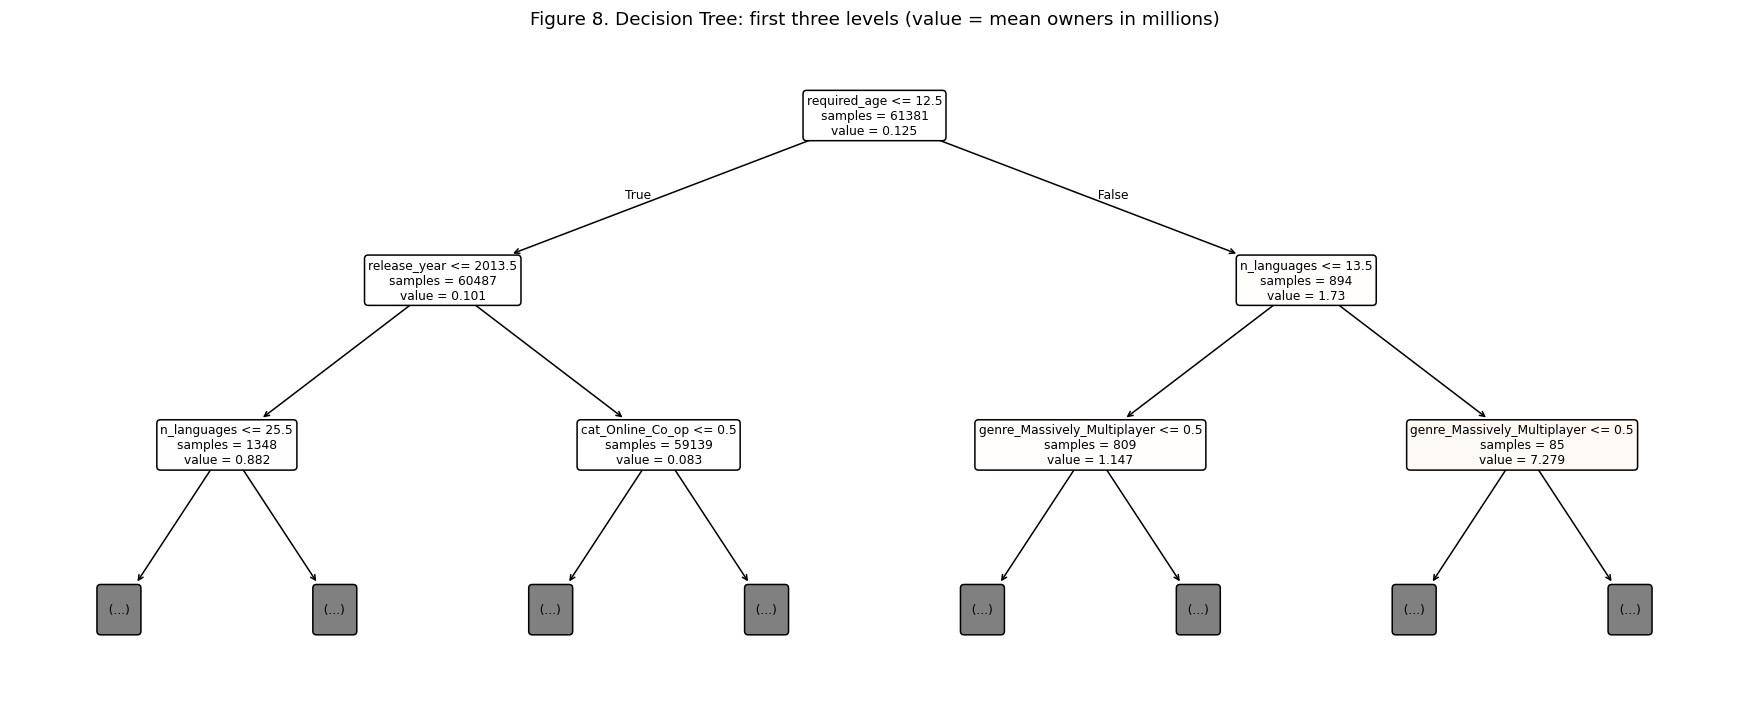

In [8]:
tree_fit = clone(decision_tree).fit(X_train, y_train)
print(f"Fitted tree on the training set: depth {tree_fit.get_depth()}, {tree_fit.get_n_leaves():,} leaves "
      f"for {len(X_train):,} training games")

fig, ax = plt.subplots(figsize=(16, 6.5))
plot_tree(tree_fit, max_depth=2, feature_names=FEATURES, filled=True, impurity=False, rounded=True,
          precision=3, fontsize=8, ax=ax)
ax.set_title("Figure 8. Decision Tree: first three levels (value = mean owners in millions)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig08_decision_tree_top_levels.png"), dpi=150)
plt.show()

**Results.** The unrestricted tree grows to depth 47 with 20,989 leaves for 61,381 training games, an average of fewer than three games per leaf. It reproduces the training data almost exactly and generalises poorly: the cross-validated R² is −1.38, with a very large standard deviation (2.01) and fold values ranging from 0.25 to −4.71. A negative R² means the predictions are further from the actual values than the training mean. The model memorises individual games, including the extreme ones, and makes large errors whenever a validation game falls into a leaf defined by one or two blockbusters.

## 6.4 Random Forest

**Method.** A Random Forest trains many decision trees, each on a random bootstrap sample of the
training games, and averages their predictions. Because each tree sees slightly different data, the
individual trees make different errors, and averaging them cancels part of these errors. This
typically makes a forest more accurate and more stable than a single tree while keeping its
ability to model non-linear effects. It is added to the parent paper's two models as the standard
ensemble extension of the Decision Tree.

**Settings.** The scikit-learn defaults are used: 100 trees, each grown without a depth limit, with
all features considered at every split.

In [9]:
random_forest = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)
t0 = time.time()
cv_results["Random Forest"] = cross_validate_model(random_forest)
print(f"5-fold cross-validation completed in {time.time() - t0:.0f}s")
cv_results["Random Forest"].round(4)

5-fold cross-validation completed in 18s


,MSE,RMSE,MAE,MAPE (%),R2
fold,,,,,
1,2.8012,1.6737,0.1525,376.9013,0.0130
2,2.8571,1.6903,0.1573,395.6379,0.0652
3,1.4474,1.2031,0.1524,390.7048,0.0144
4,1.4523,1.2051,0.1598,489.5156,-0.0569
5,2.7295,1.6521,0.1541,393.0815,0.0271


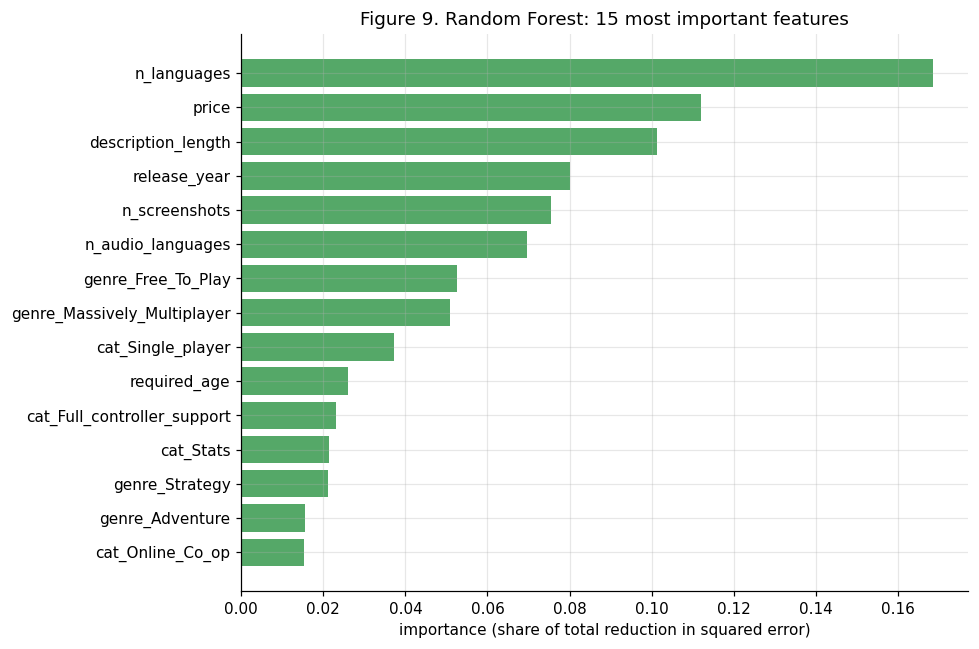

In [10]:
forest_fit = clone(random_forest).fit(X_train, y_train)
importance = pd.Series(forest_fit.feature_importances_, index=FEATURES).sort_values(ascending=False)
importance.rename("importance").to_frame().to_csv(os.path.join(TAB_DIR, "table5_random_forest_importance.csv"))

top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color=GREEN)
ax.set_xlabel("importance (share of total reduction in squared error)")
ax.set_title("Figure 9. Random Forest: 15 most important features")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig09_random_forest_importance.png"), dpi=150)
plt.show()

**Results.** The forest has the lowest mean absolute error of the three models (0.155 million, against 0.190 for the baseline) and a lower MAPE (409% against 841%), but its cross-validated R² is close to zero (0.013 ± 0.044; one fold is negative). Averaging 100 trees removes most of the single tree's instability, but on the original owner scale the squared-error measures remain dominated by the few largest games in each fold.

**Feature importance (Figure 9).** The most used features are supported languages, price, description length, release year, screenshots and full-audio languages, followed by the free-to-play and massively multiplayer genres. Impurity-based importance favours numeric features with many possible split points over binary flags, so the ranking of numeric against binary features should be read with caution.

## 6.5 Cross-validated comparison

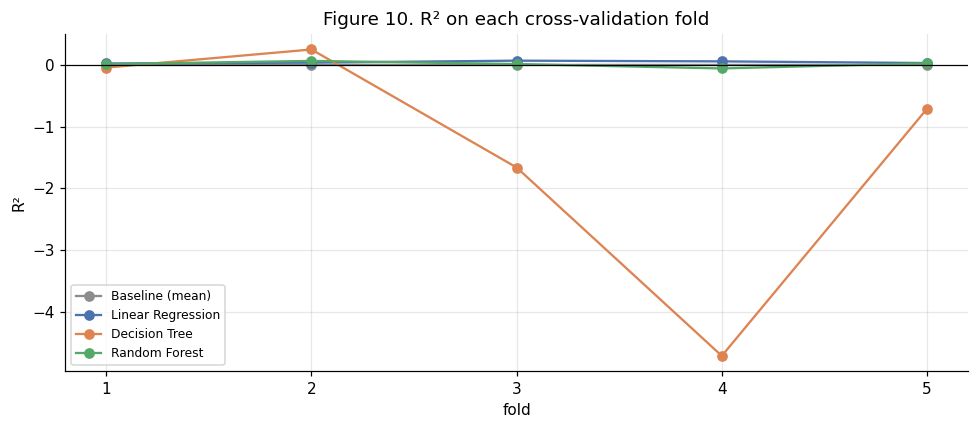

,MSE,RMSE,MAE,MAPE (%),R2
Baseline (mean),2.3086 ± 0.8164,1.4984 ± 0.2814,0.1896 ± 0.0044,840.8045 ± 12.6566,-0.0000 ± 0.0000
Linear Regression,2.2192 ± 0.8154,1.4673 ± 0.2877,0.2327 ± 0.0014,1135.0911 ± 36.1707,0.0436 ± 0.0191
Decision Tree,4.3620 ± 2.1689,2.0408 ± 0.4965,0.1797 ± 0.0238,414.4435 ± 132.9088,-1.3756 ± 2.0051
Random Forest,2.2575 ± 0.7387,1.4849 ± 0.2567,0.1552 ± 0.0032,409.1682 ± 45.4962,0.0126 ± 0.0442


In [11]:
METRICS = ["MSE", "RMSE", "MAE", "MAPE (%)", "R2"]
means = pd.DataFrame({m: cv_results[m].mean() for m in MODEL_ORDER}).T[METRICS]
sds = pd.DataFrame({m: cv_results[m].std() for m in MODEL_ORDER}).T[METRICS]
means.join(sds, rsuffix=" SD").to_csv(os.path.join(TAB_DIR, "table6_cross_validation.csv"))
table6 = means.map(lambda v: f"{v:.4f}") + " ± " + sds.map(lambda v: f"{v:.4f}")

per_fold_r2 = pd.DataFrame({m: cv_results[m]["R2"] for m in MODEL_ORDER})
fig, ax = plt.subplots(figsize=(9, 4))
for m in MODEL_ORDER:
    ax.plot(per_fold_r2.index, per_fold_r2[m], marker="o", color=MODEL_COLORS[m], label=m)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(per_fold_r2.index)
ax.set_xlabel("fold")
ax.set_ylabel("R²")
ax.set_title("Figure 10. R² on each cross-validation fold")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig10_cv_r2_by_fold.png"), dpi=150)
plt.show()
table6.style.set_caption("Table 6. 5-fold cross-validation on the training set (mean ± SD)")

**Interpretation.**
- **No model explains a meaningful share of the variance.** The best cross-validated R² is 0.044 (Linear Regression); Random Forest reaches 0.013 and the Decision Tree is worse than the baseline (−1.38).
- **The metrics disagree.** Linear Regression has the best R² but the worst MAE; Random Forest has the best MAE and MAPE but an R² near zero. R², MSE and RMSE are governed by the largest games, whereas MAE and MAPE are governed by the typical game.
- **The evaluation is unstable.** Even the baseline's MSE ranges from 1.37 to 3.06 across folds (Table 6 standard deviations), depending on which blockbusters each fold happens to contain.
- **MAPE is several hundred percent for every model, including the baseline (841%).** Most games have 0.01 million owners, so a prediction of 0.1 million is a 900% error. MAPE is therefore not informative for this target.

---
# 7. Validation

## 7.1 Test set performance

Each model is trained on the full training set and evaluated once on the test set. Table 7 is the
equivalent of the parent paper's Table II.

In [12]:
final_models = {"Baseline (mean)": baseline, "Linear Regression": lin_reg,
                "Decision Tree": decision_tree, "Random Forest": random_forest}
fitted, test_pred, train_pred, rows = {}, {}, {}, []
for name in MODEL_ORDER:
    fitted[name] = clone(final_models[name]).fit(X_train, y_train)
    test_pred[name] = fitted[name].predict(X_test)
    train_pred[name] = fitted[name].predict(X_train)
    rows.append({"Model": name, **compute_metrics(y_test, test_pred[name])})
table7 = pd.DataFrame(rows).set_index("Model")
table7.to_csv(os.path.join(TAB_DIR, "table7_test_set.csv"))
table7.style.format("{:.4f}").set_caption("Table 7. Test set performance (15,346 games not used in training)")

,MSE,RMSE,MAE,MAPE (%),R2
Model,,,,,
Baseline (mean),3.3134,1.8203,0.1955,846.9428,-0.0000
Linear Regression,3.2027,1.7896,0.2384,1130.0509,0.0334
Decision Tree,4.5522,2.1336,0.1727,419.3643,-0.3739
Random Forest,2.1877,1.4791,0.1571,407.3141,0.3397


**Results.** On the test set, Random Forest achieves R² = 0.340 and the lowest MAE (0.157 million). The Decision Tree is worse than the baseline (R² = −0.374), and Linear Regression explains 3.3% of the variance with a higher MAE than the baseline. Random Forest's test R² is much higher than its cross-validated R² (0.013); Section 7.4 shows why this single figure should not be relied on.

## 7.2 Training versus test performance

Comparing each model's score on the data it was trained on with its score on the test set shows
whether it has learned general patterns or memorised the training games (overfitting).

In [13]:
fit_check = pd.DataFrame({
    "Training R2": {m: r2_score(y_train, train_pred[m]) for m in MODEL_ORDER},
    "Test R2": {m: r2_score(y_test, test_pred[m]) for m in MODEL_ORDER},
    "Training MAE": {m: mean_absolute_error(y_train, train_pred[m]) for m in MODEL_ORDER},
    "Test MAE": {m: mean_absolute_error(y_test, test_pred[m]) for m in MODEL_ORDER},
}).loc[MODEL_ORDER]
fit_check.to_csv(os.path.join(TAB_DIR, "table8_training_vs_test.csv"))
fit_check.style.format("{:.4f}").set_caption("Table 8. Training versus test performance")

,Training R2,Test R2,Training MAE,Test MAE
Baseline (mean),0.0000,-0.0000,0.1896,0.1955
Linear Regression,0.0423,0.0334,0.2316,0.2384
Decision Tree,0.9913,-0.3739,0.0025,0.1727
Random Forest,0.8515,0.3397,0.0591,0.1571


**Interpretation.**
- **Decision Tree: severe overfitting.** Training R² is 0.991 and training MAE is 0.0025 million, against −0.374 and 0.173 on the test set. The tree has memorised the training games.
- **Random Forest: substantial overfitting.** Training R² is 0.852, against 0.340 on the test set and 0.013 in cross-validation.
- **Linear Regression: underfitting.** Training and test R² are both low (0.042 and 0.033). The model is too simple for the relationship on the original owner scale rather than too flexible.

## 7.3 Predicted versus actual owners

The parent paper presented its predictions as a bar plot and as a scatter plot against release year
(its Figures 2 and 3). Figure 11 shows the equivalent for the test set: (a) actual versus predicted
owners for each game, on logarithmic axes because owners span four orders of magnitude, and (b) the
mean actual and mean predicted owners for each SteamSpy owner range.

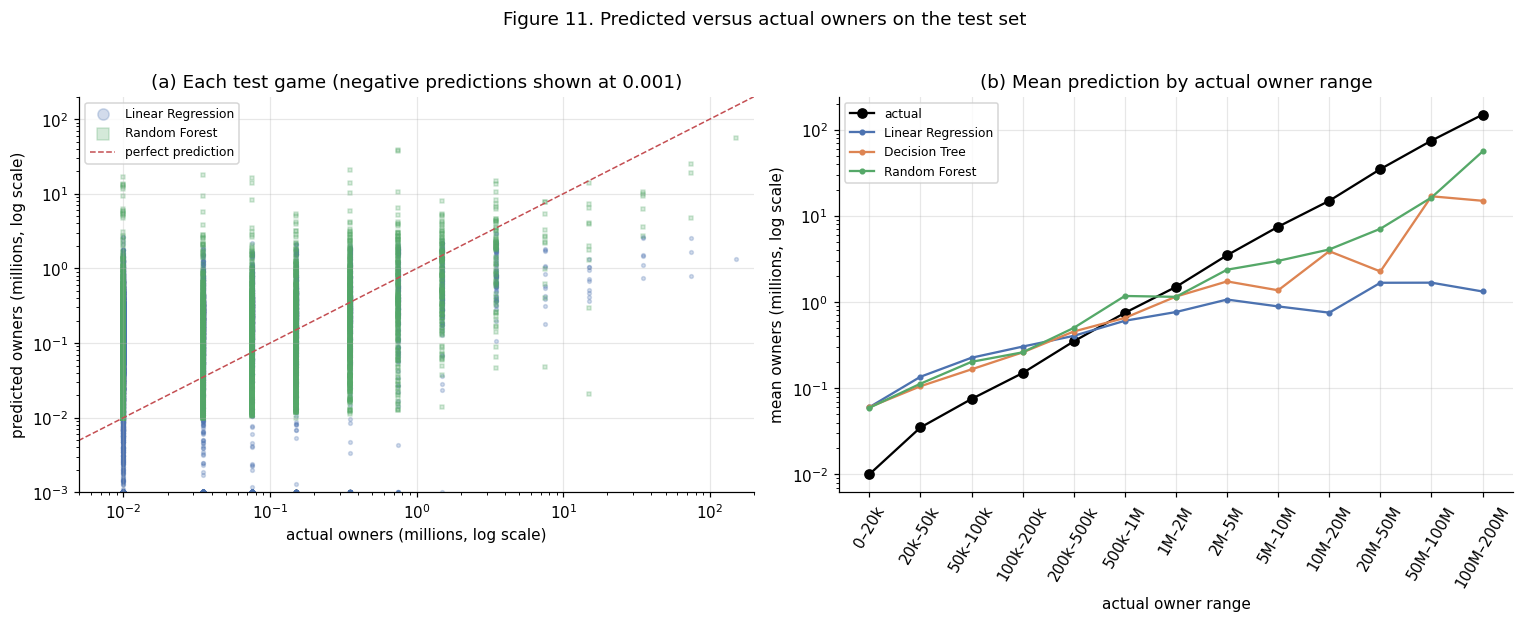

Negative predictions on the test set - Linear Regression: 38.9%


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ax = axes[0]
for m, marker in [("Linear Regression", "o"), ("Random Forest", "s")]:
    ax.scatter(y_test, np.clip(test_pred[m], 1e-3, None), s=6, alpha=0.25, color=MODEL_COLORS[m], label=m, marker=marker)
lims = [1e-3, 200]
ax.plot(lims, lims, color=RED, ls="--", lw=1, label="perfect prediction")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(5e-3, 200)
ax.set_ylim(*lims)
ax.set_xlabel("actual owners (millions, log scale)")
ax.set_ylabel("predicted owners (millions, log scale)")
ax.set_title("(a) Each test game (negative predictions shown at 0.001)")
ax.legend(markerscale=3, fontsize=8)

ranges = test.groupby("estimated_owners")[TARGET].mean().sort_values()
by_range = pd.DataFrame({"actual": ranges})
for m in ["Linear Regression", "Decision Tree", "Random Forest"]:
    by_range[m] = pd.Series(test_pred[m], index=test.index).groupby(test["estimated_owners"]).mean()
ax = axes[1]
xs = np.arange(len(by_range))
ax.plot(xs, by_range["actual"], color="black", marker="o", label="actual")
for m in ["Linear Regression", "Decision Tree", "Random Forest"]:
    ax.plot(xs, by_range[m].clip(lower=1e-3), marker=".", color=MODEL_COLORS[m], label=m)
ax.set_yscale("log")
ax.set_xticks(xs)
ax.set_xticklabels([range_label(o) for o in by_range.index], rotation=60)
ax.set_xlabel("actual owner range")
ax.set_ylabel("mean owners (millions, log scale)")
ax.set_title("(b) Mean prediction by actual owner range")
ax.legend(fontsize=8)
fig.suptitle("Figure 11. Predicted versus actual owners on the test set", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig11_predicted_vs_actual.png"), dpi=150, bbox_inches="tight")
plt.show()
print(f"Negative predictions on the test set - Linear Regression: {(test_pred['Linear Regression'] < 0).mean():.1%}")

**Interpretation.**
- **Panel (a).** Linear Regression predicts almost every game within a narrow band: 98% of its predictions lie between −0.23 and 1.49 million, and 38.9% are negative, an impossible number of owners. Random Forest's predictions spread further, but for the many small games they are still several times too high.
- **Panel (b).** All three models over-predict the lowest range (a mean prediction of about 0.06 million against an actual 0.01 million) and increasingly under-predict the larger ranges. Linear Regression never predicts more than 3 million, so games with 50–150 million owners are predicted at about 1.3–1.7 million.
- **Ranking information is present.** For all three models the mean prediction rises steadily with the actual owner range. The features separate small, medium and large games in relative terms, even though the absolute predictions are poor. This is consistent with the Spearman correlations in Notebook 2.

## 7.4 Where the errors come from

The table groups test games by their actual owner range and reports the share of games in each
range and each model's share of the total squared error.

In [15]:
err = pd.DataFrame({"range": test["estimated_owners"], "actual": y_test})
for m in ["Linear Regression", "Decision Tree", "Random Forest"]:
    err[m] = (test_pred[m] - y_test) ** 2
order = test.drop_duplicates("estimated_owners").sort_values(TARGET)["estimated_owners"]
error_share = err.groupby("range").agg(games=("actual", "size"), **{
    f"{m}: share of squared error": (m, "sum") for m in ["Linear Regression", "Decision Tree", "Random Forest"]}).reindex(order)
error_share["share of games"] = error_share["games"] / error_share["games"].sum()
for m in ["Linear Regression", "Decision Tree", "Random Forest"]:
    col = f"{m}: share of squared error"
    error_share[col] = error_share[col] / error_share[col].sum()
error_share = error_share[["games", "share of games"] + [c for c in error_share.columns if "squared" in c]]
error_share.to_csv(os.path.join(TAB_DIR, "table9_error_by_owner_range.csv"))
error_share.style.format({"games": "{:,}", **{c: "{:.1%}" for c in error_share.columns if c != "games"}}) \
    .set_caption("Table 9. Share of squared error by actual owner range (test set)")

,games,share of games,Linear Regression: share of squared error,Decision Tree: share of squared error,Random Forest: share of squared error
estimated_owners,,,,,
0 - 20000,"10,769",70.2%,1.2%,33.3%,4.6%
20000 - 50000,"1,995",13.0%,0.3%,2.2%,1.7%
50000 - 100000,959,6.2%,0.2%,2.0%,1.8%
100000 - 200000,645,4.2%,0.2%,2.1%,0.5%
200000 - 500000,515,3.4%,0.2%,2.4%,2.7%
500000 - 1000000,208,1.4%,0.1%,0.9%,9.1%
1000000 - 2000000,148,1.0%,0.3%,2.4%,0.7%
2000000 - 5000000,75,0.5%,1.0%,1.0%,2.0%
5000000 - 10000000,12,0.1%,1.1%,0.7%,1.0%


**Interpretation.** 70% of test games are in the lowest owner range, yet they account for only 1% (Linear Regression) to 5% (Random Forest) of the squared error. The 20 games with 10 million owners or more, 0.13% of the test set, account for 96% of Linear Regression's squared error, 76% of Random Forest's and 53% of the Decision Tree's. Metrics based on squared error (MSE, RMSE, R²) therefore measure almost exclusively how well a model predicts about twenty blockbusters. The Decision Tree is the exception in the lowest range (33% of its error), because some small games fall into leaves shaped by large ones.

**Sensitivity check.** Because a few games carry most of the squared error, R² is recomputed on the
test set without the games that have 10 million owners or more, and the largest test games are
listed with each model's prediction.

In [16]:
big = (y_test >= 10).values
sensitivity = pd.DataFrame({
    "Test R2 (all games)": {m: r2_score(y_test, test_pred[m]) for m in MODEL_ORDER[1:]},
    f"Test R2 without the {big.sum()} games >= 10M owners": {m: r2_score(y_test[~big], test_pred[m][~big]) for m in MODEL_ORDER[1:]},
})
sensitivity.to_csv(os.path.join(TAB_DIR, "table10_blockbuster_sensitivity.csv"))
display(sensitivity.style.format("{:.3f}").set_caption("Table 10. Test R² with and without the largest games"))

largest = test.assign(**{m: test_pred[m] for m in MODEL_ORDER[1:]}).nlargest(8, TARGET)[["name", TARGET] + MODEL_ORDER[1:]]
largest.set_index("name").style.format("{:.2f}").set_caption("Largest test games: actual and predicted owners (millions)")

,Test R2 (all games),Test R2 without the 20 games >= 10M owners
Linear Regression,0.033,-0.095
Decision Tree,-0.374,-15.227
Random Forest,0.340,-3.010


,owners_millions,Linear Regression,Decision Tree,Random Forest
name,,,,
Counter-Strike 2,150.00,1.33,15.00,56.04
Left 4 Dead 2,75.00,1.66,15.00,25.42
Palworld,75.00,0.80,0.75,4.74
Grand Theft Auto V Legacy,75.00,2.57,35.00,18.97
Dead by Daylight,35.00,2.66,0.35,10.07
Brawlhalla,35.00,0.75,3.50,9.38
ARK: Survival Evolved,35.00,1.09,7.50,3.54
World of Warships,35.00,1.53,0.75,2.68


**Interpretation.** Without the 20 largest games, every model has a negative R²: −0.10 for Linear Regression, −3.0 for Random Forest and −15.2 for the Decision Tree. For the remaining 99.9% of games, all models predict worse than simply using those games' average. Random Forest's test R² of 0.34 comes from placing a few blockbusters in the right direction, for example Counter-Strike 2 (predicted 56 million, actual 150 million), Left 4 Dead 2 (25 against 75 million) and Grand Theft Auto V (19 against 75 million). Its training set contains comparable titles with very high owner counts (Dota 2, PUBG and Apex Legends at 150 million), so the result depends on which blockbusters fall on each side of the split. This explains the gap between its test R² and its cross-validated R².

---
# 8. Decision Making

## 8.1 Model comparison

In [17]:
summary = pd.DataFrame({
    "CV R2": means["R2"], "CV R2 SD": sds["R2"], "Test R2": table7["R2"],
    "Test MAE": table7["MAE"], "Test RMSE": table7["RMSE"], "Training R2": fit_check["Training R2"],
}).loc[MODEL_ORDER]
summary.style.format("{:.4f}").set_caption("Model comparison summary")

,CV R2,CV R2 SD,Test R2,Test MAE,Test RMSE,Training R2
Baseline (mean),-0.0000,0.0000,-0.0000,0.1955,1.8203,0.0000
Linear Regression,0.0436,0.0191,0.0334,0.2384,1.7896,0.0423
Decision Tree,-1.3756,2.0051,-0.3739,0.1727,2.1336,0.9913
Random Forest,0.0126,0.0442,0.3397,0.1571,1.4791,0.8515


**Decision.** None of the baseline models is suitable for predicting owners on the original scale. Random Forest has the lowest absolute error on both the cross-validation folds and the test set, and it is the only model that represents non-linear relationships without memorising the training data outright. It is therefore the model to carry forward. Its apparent test R² should not be reported as its performance, because it depends on a handful of games. Linear Regression, the parent paper's preferred model, explains less than 5% of the variance and predicts negative owners for 39% of games. The Decision Tree with default settings overfits to the point of being worse than the mean.

## 8.2 Variables associated with sales

Both models point to the same characteristics, although with low overall accuracy:
- **Localisation and production scale.** Supported languages is the most important feature in the Random Forest and has a positive Linear Regression coefficient; price, description length and screenshots follow.
- **Online and multiplayer design.** Free-to-play, massively multiplayer, co-op and online co-op are positive in both models.
- **Release year.** Later releases have fewer owners, reflecting time on sale and market growth rather than game quality.
- **Negative indicators.** Education, VR-only and violent-content titles, and the single-player flag once other features are controlled for.

These are associations learned from a model with little explanatory power and should be confirmed after the modifications listed below.

## 8.3 Issues identified and next steps

The baseline identifies the following issues. Each is linked to the evidence above and to a modification for the next iteration.

| # | Issue | Evidence | Proposed modification |
|---|---|---|---|
| 1 | The target's extreme skew dominates model fitting and the error metrics | 0.13% of test games cause 76–96% of the squared error; R² is negative for all models without them (Table 10) | Model log10(owners) instead of owners, the standard treatment for a quantity that spans several orders of magnitude |
| 2 | Evaluation is unstable | Fold-to-fold R² SD up to 2.0; Random Forest R² 0.01 in CV against 0.34 on the test set | Follows largely from issue 1; report metrics on the log scale |
| 3 | Linear Regression predicts impossible values | 39% of test predictions are negative | A log target guarantees positive predictions after back-transformation |
| 4 | The Decision Tree overfits | Depth 47 and 20,989 leaves; training R² 0.99 against test R² −0.37 | Limit tree depth and minimum leaf size, chosen by cross-validation |
| 5 | Random Forest overfits | Training R² 0.85 against CV R² 0.01 | Tune the minimum leaf size and features per split by cross-validation |
| 6 | MAPE is not informative | 400–1,100% for every model, 847% for the baseline | Replace with MAE on the log scale, or with a classification view (e.g. predicting whether a game reaches 100,000 owners) |
| 7 | Release year mixes time on sale with game characteristics | Strongest correlation with owners (−0.27); mean owners fall with release year | Compare games within their release year, or train on earlier and test on later releases |
| 8 | The feature set covers basic store-page fields only | Mean predictions rank games correctly (Figure 11b) but with low precision | Add further information available before release, such as developer and publisher track record |

## 8.4 Conclusion

Applied with the target on its original scale, default model settings and a random split, the parent paper's two methods and Random Forest do not produce a useful model of Steam game sales from information available at release. Cross-validated R² is 0.044 for Linear Regression, 0.013 for Random Forest and −1.38 for the Decision Tree, and the single test-set R² of 0.34 for Random Forest is driven by a few blockbusters. In contrast with the parent paper's R² of 1.000, removing the predictors that are not available at release leaves the same methods explaining almost none of the variance on the original owner scale.

The analysis also shows why. The main obstacle is the distribution of the target rather than the choice of algorithm: sales are so concentrated that squared-error methods fit and evaluate a few dozen games. At the same time, all models rank games in the right order on average, so the features do carry information. The issues in Section 8.3 define the modifications for the next iteration, starting with a logarithmic target.